# Data Mining Lab Assignment

## Book Recommender System Using a Medallion Data Lake

**Name:** Mohd Asif

**Roll Number:** MSD25009

**Programme:** M.Sc. Data Science

**Institute:** Indian Institute of Information Technology, Lucknow

### Objective

To process the raw Book-Crossing dataset through a
Bronze-Silver-Gold Medallion Data Lake architecture
and develop an item-based collaborative filtering
recommendation system using cosine similarity.

### Dataset

Book-Crossing Dataset:

- BX-Users.csv
- BX-Books.csv
- BX-Book-Ratings.csv

In [2]:
import os
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datetime import datetime
from scipy.sparse import csr_matrix, save_npz, load_npz
from sklearn.neighbors import NearestNeighbors

Step 1: Set Up the Data Lake and Build the Bronze Layer

• In Colab, create the folders bronze/, silver/ and gold/.

• Download the three raw files and load them exactly as they are. Note that the files use semicolon separators and non-UTF-8 encoding, so handle this while reading.

• Add an ingestion_timestamp column to each table and save the tables to bronze/ as Parquet.

• Do not clean anything in this layer. Bronze is the untouched copy of the source.

In [4]:
# to create the data lake folders
for folder in ['raw', 'bronze', 'silver', 'gold']:
  os.makedirs(folder, exist_ok=True)

print('Data lake folders created successfully')

Data lake folders created successfully


In [5]:
with open("raw/BX-Books.csv", encoding="latin-1") as f:
    for i, line in enumerate(f, start=1):
        if 6449 <= i <= 6455:
            print(f"Line {i}: {line}")

Line 6449: "0297828991";"Mr Foreigner";"Matthew Kneale";"2003";"Trafalgar Square";"http://images.amazon.com/images/P/0297828991.01.THUMBZZZ.jpg";"http://images.amazon.com/images/P/0297828991.01.MZZZZZZZ.jpg";"http://images.amazon.com/images/P/0297828991.01.LZZZZZZZ.jpg"

Line 6450: "0061013722";"The Clairvoyant";"Marian Thurm";"1999";"HarperTorch";"http://images.amazon.com/images/P/0061013722.01.THUMBZZZ.jpg";"http://images.amazon.com/images/P/0061013722.01.MZZZZZZZ.jpg";"http://images.amazon.com/images/P/0061013722.01.LZZZZZZZ.jpg"

Line 6451: "0451163540";"Triple";"Ken Follett";"1991";"Signet Book";"http://images.amazon.com/images/P/0451163540.01.THUMBZZZ.jpg";"http://images.amazon.com/images/P/0451163540.01.MZZZZZZZ.jpg";"http://images.amazon.com/images/P/0451163540.01.LZZZZZZZ.jpg"

Line 6452: "0735201994";"Peterman Rides Again: Adventures Continue with the Real \"J. Peterman\" Through Life &amp; the Catalog Business";"John Peterman";"2000";"Prentice Hall Art";"http://images.amazon

"Peterman Rides Again: Adventures Continue with the Real \"J. Peterman\" Through Life &amp; the Catalog Business"


Pandas is incorrectly interpreting these quotation marks as field boundaries.

We can resolve this by specifying escapechar="\\" when reading the CSV file. This is a parsing correction, not data cleaning, so it is consistent with the Bronze layer requirements.

### Raw Data Ingestion

The Book-Crossing dataset uses semicolon-separated
fields and Latin-1 encoding.

During ingestion, a parsing error was encountered
because some book titles contained escaped double
quotation marks.

The escapechar parameter was used to interpret
these characters correctly without intentionally
discarding or cleaning any records.

All source columns and missing-value representations
were retained in the Bronze layer.

In [6]:
# load the raw datasets
# as mentioned, the files use semicolon separators and non-UTF-8 encoding.
# therefore, use sep=";" and encoding="latin-1".

users = pd.read_csv(
    "raw/BX-Users.csv",
    sep=";",
    encoding="latin-1",
    dtype=str,
    keep_default_na=False,
    escapechar="\\"
)

books = pd.read_csv(
    "raw/BX-Books.csv",
    sep=";",
    encoding="latin-1",
    dtype=str,
    keep_default_na=False,
    escapechar="\\"
)

ratings = pd.read_csv(
    "raw/BX-Book-Ratings.csv",
    sep=";",
    encoding="latin-1",
    dtype=str,
    keep_default_na=False,
    escapechar="\\"
)

In [7]:
# to add ingestion timestamp

timestamp = pd.Timestamp.now(tz="UTC")

users['ingestion_timestamp'] = timestamp
books['ingestion_timestamp'] = timestamp
ratings['ingestion_timestamp'] = timestamp

In [8]:
# to save the bronze layer
users.to_parquet("bronze/users.parquet", index=False)
books.to_parquet("bronze/books.parquet", index=False)
ratings.to_parquet("bronze/ratings.parquet", index=False)

print("Bronze layer created successfully")
print(os.listdir("bronze"))

Bronze layer created successfully
['users.parquet', 'ratings.parquet', 'books.parquet']


Step 2: Explore the Bronze Data (EDA) Read the Bronze tables back and examine them. For each item below, write one line in a markdown cell saying what you found and what you will do about it in Silver.

• Shape, data types and missing-value count of each table

• Distribution of ratings (note how many are 0)

• Distribution of user ages and of publication years (look for impossible values)

• Number of ratings per user and per book (most will have very few)

• Matrix sparsity: the percentage of possible user-book pairs that actually have a rating

In [9]:
# to load bronze data
users = pd.read_parquet("bronze/users.parquet")
books = pd.read_parquet("bronze/books.parquet")
ratings = pd.read_parquet("bronze/ratings.parquet")

In [10]:
# to know shape, datatype, and missing values

print("Dataset: ", 'Users')
print("Shape: ", users.shape)

print("\nData Types: ")
print(users.dtypes)

print("\nMissing Values: ")
print(users.replace(["", "NULL"], np.nan).isnull().sum())

Dataset:  Users
Shape:  (278858, 4)

Data Types: 
User-ID                             object
Location                            object
Age                                 object
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values: 
User-ID                     0
Location                    0
Age                    110762
ingestion_timestamp         0
dtype: int64


In [11]:
print("\nDataset: ", 'Books')
print("Shape: ", books.shape)

print("\nData Types: ")
print(books.dtypes)

print("\nMissing Values: ")
print(books.replace(["", "NULL"], np.nan).isnull().sum())


Dataset:  Books
Shape:  (271379, 9)

Data Types: 
ISBN                                object
Book-Title                          object
Book-Author                         object
Year-Of-Publication                 object
Publisher                           object
Image-URL-S                         object
Image-URL-M                         object
Image-URL-L                         object
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values: 
ISBN                   0
Book-Title             0
Book-Author            0
Year-Of-Publication    0
Publisher              0
Image-URL-S            0
Image-URL-M            0
Image-URL-L            0
ingestion_timestamp    0
dtype: int64


In [12]:
print("Dataset: ", 'Ratings')
print("Shape: ", ratings.shape)

print("\nData Types: ")
print(ratings.dtypes)

print("\nMissing Values: ")
print(ratings.replace(["", "NULL"], np.nan).isnull().sum())

Dataset:  Ratings
Shape:  (1149780, 4)

Data Types: 
User-ID                             object
ISBN                                object
Book-Rating                         object
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values: 
User-ID                0
ISBN                   0
Book-Rating            0
ingestion_timestamp    0
dtype: int64


Record the actual missing-value counts and explain which columns require conversion or imputation in Silver.

Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64
Zero ratings: 716109
Percentage of zero ratings: 62.28226269373272


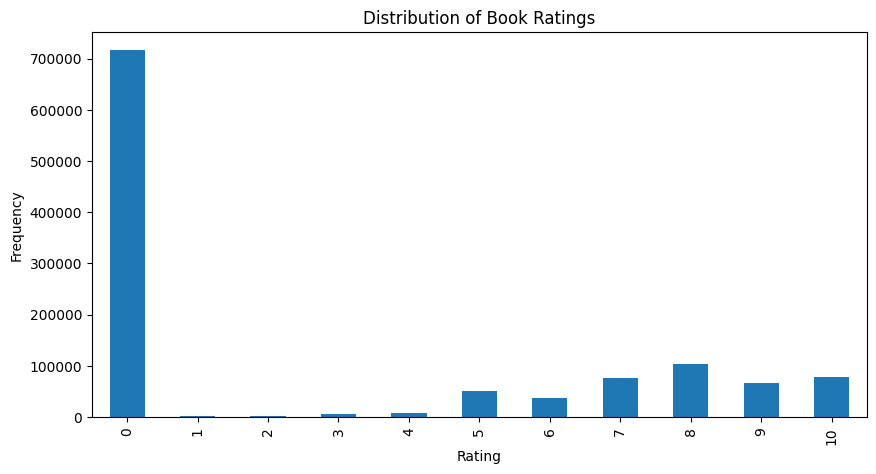

In [13]:
rating_values = pd.to_numeric(
    ratings["Book-Rating"], errors="coerce"
)

print(rating_values.value_counts().sort_index())

print("Zero ratings:", (rating_values == 0).sum())

print("Percentage of zero ratings:",
      (rating_values == 0).mean() * 100)

rating_values.value_counts().sort_index().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()

Ages outside the range 5–100 will be treated as missing values and replaced with the median valid age.

Age statistics:
count    1820.000000
mean       34.691758
std         9.899330
min         9.000000
25%        29.000000
50%        32.000000
75%        38.250000
max        90.000000
Name: Age, dtype: float64

Missing ages: 0
Ages below 5: 0
Ages above 100: 0
Total invalid ages: 0


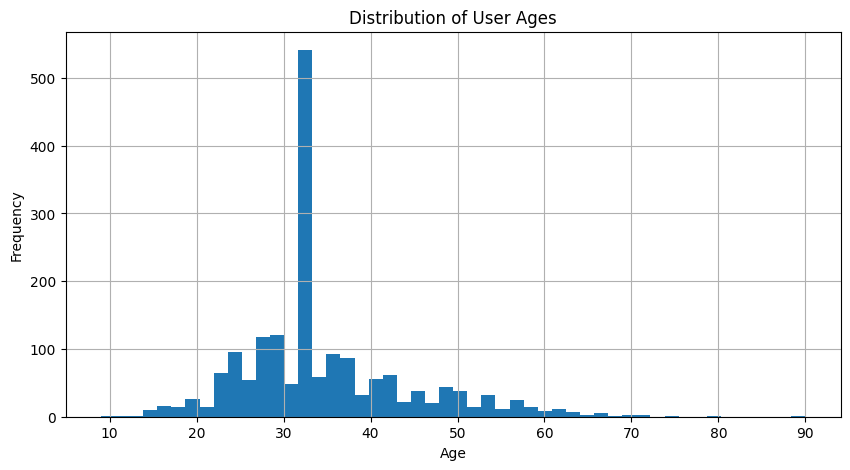

In [64]:
# to examine the distribution of user ages

ages = pd.to_numeric(users["Age"], errors="coerce")

print("Age statistics:")
print(ages.describe())

print("\nMissing ages:", ages.isna().sum())

print("Ages below 5:", (ages < 5).sum())

print("Ages above 100:", (ages > 100).sum())

print("Total invalid ages:",
      ((ages < 5) | (ages > 100)).sum())

ages.hist(bins=50, figsize=(10, 5))

plt.title("Distribution of User Ages")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

count    271379.000000
mean       1959.756050
std         258.011363
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64
Invalid publication years: 4630


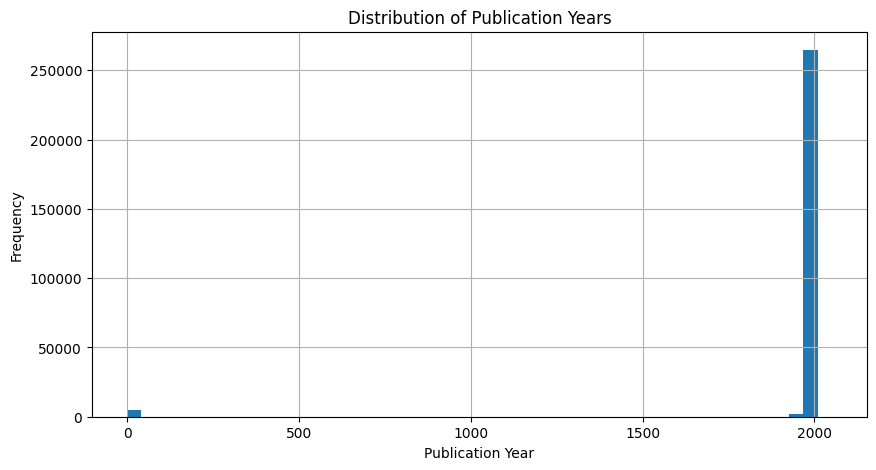

In [14]:
years = pd.to_numeric(
    books["Year-Of-Publication"],
    errors="coerce"
)

current_year = datetime.now().year

print(years.describe())

print("Invalid publication years:",
      ((years <= 0) | (years > current_year)).sum())

years.hist(bins=50, figsize=(10, 5))

plt.title("Distribution of Publication Years")
plt.xlabel("Publication Year")
plt.ylabel("Frequency")
plt.show()

Zero, future and invalid publication years will be converted to missing values.

In [15]:
user_counts = ratings.groupby("User-ID").size()
book_counts = ratings.groupby("ISBN").size()

print("Ratings per user:")
print(user_counts.describe())

print("\nRatings per book:")
print(book_counts.describe())

Ratings per user:
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64

Ratings per book:
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64


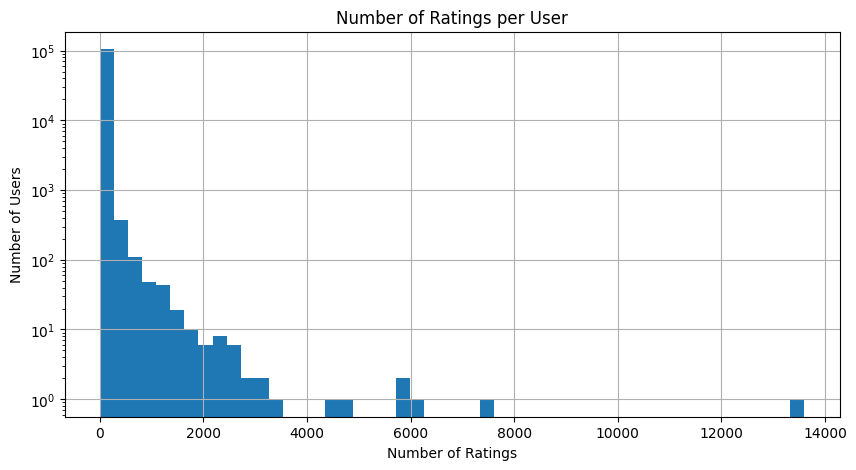

In [16]:
plt.figure(figsize=(10, 5))

user_counts.hist(bins=50)
plt.yscale("log")
plt.title("Number of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")
plt.show()

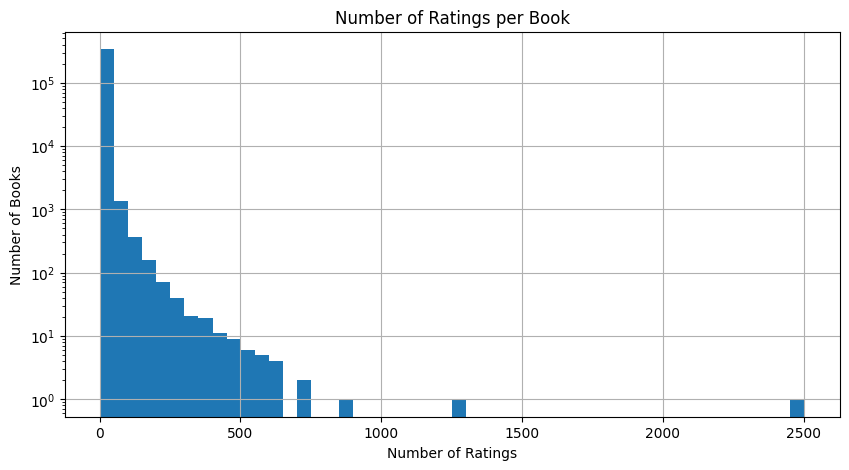

In [17]:
plt.figure(figsize=(10, 5))

book_counts.hist(bins=50)
plt.yscale("log")
plt.title("Number of Ratings per Book")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Books")
plt.show()

### Matrix Density and Sparsity

Matrix density represents the percentage of possible
user-book pairs that have an observed rating.

$$
\text{Density} =
\frac{\text{Observed user-book pairs}}
{\text{Total users} \times \text{Total books}}
\times 100
$$

$$
\text{Sparsity} = 100 - \text{Density}
$$

In [63]:
# Calculate rating matrix density and sparsity

n_users = ratings["User-ID"].nunique()
n_books = ratings["ISBN"].nunique()

observed = ratings[["User-ID", "ISBN"]].drop_duplicates().shape[0]

possible = n_users * n_books

density = (observed / possible) * 100
sparsity = 100 - density

print("Unique users:", n_users)
print("Unique books:", n_books)
print("Observed user-book pairs:", observed)
print("Possible user-book pairs:", possible)
print(f"Density: {density:.6f}%")
print(f"Sparsity: {sparsity:.6f}%")

Unique users: 1820
Unique books: 2030
Observed user-book pairs: 41469
Possible user-book pairs: 3694600
Density: 1.122422%
Sparsity: 98.877578%


Step 3: Clean the Data and Build the Silver Layer Apply the following and save the cleaned tables to silver/:

• Remove duplicate rows (users, books and ratings). • Remove ratings of 0 (they mean 'no explicit rating') and keep ratings from 1 to 10.

• Fix user ages: set values below 5 or above 100 to null, then fill nulls with the median age.

• Split the user Location text into city, state and country columns.

• Fix publication years: set 0 or future years to null.

• Clean text columns: strip extra spaces, standardise case, and drop the image-URL columns you do not need.

• Keep only ratings whose book and user exist in the books and users tables.

• Keep only users and books that have at least a minimum number of ratings (for example 10). Choose a threshold, state it, and justify it using your EDA.

In [19]:
# to remove duplicates and ingestion metadata
users = users.drop(columns='ingestion_timestamp')
books = books.drop(columns='ingestion_timestamp')
ratings = ratings.drop(columns='ingestion_timestamp')

users = users.drop_duplicates()
books = books.drop_duplicates()
ratings = ratings.drop_duplicates()

In [20]:
# to clean ratings
ratings["Book-Rating"] = pd.to_numeric(ratings['Book-Rating'], errors='coerce')

ratings = ratings[ratings["Book-Rating"].between(1, 10)].copy()

print("Remaining ratings:", len(ratings))


Remaining ratings: 433671


In [56]:
# to clean user ages
users['Age'] = pd.to_numeric(users['Age'], errors='coerce')

# Correct parentheses to ensure proper operator precedence
users.loc[(users['Age'] < 5) | (users['Age'] > 100), "Age"] = np.nan

median_age = users['Age'].median()

users["Age"] = users["Age"].fillna(median_age)

print("Median age:",  median_age)

Median age: 32.0


In [22]:
# to split user location
location = users['Location'].str.rsplit(",", n=2, expand=True)

location = location.reindex(columns=range(3))

users['City'] = location[0]
users['State'] = location[1]
users['Country'] = location[2]

for col in ['City', 'State', 'Country']:
  users[col] = users[col].str.strip().str.lower()

users = users.drop(columns=['Location'])

display(users.head())

,User-ID,Age,City,State,Country
0,1,32.0,nyc,new york,usa
1,2,18.0,stockton,california,usa
2,3,32.0,moscow,yukon territory,russia
3,4,17.0,porto,v.n.gaia,portugal
4,5,32.0,farnborough,hants,united kingdom


In [23]:
# to clean publication years
books['Year-Of-Publication'] = pd.to_numeric(
    books['Year-Of-Publication'], errors='coerce'
)

current_year = datetime.now().year

books.loc[
    (books['Year-Of-Publication'] <= 0) |
    (books['Year-Of-Publication'] > current_year),
    'Year-Of-Publication'
] = np.nan

print("Median publication year:", books['Year-Of-Publication'].median())

Median publication year: 1996.0


In [24]:
# to clean the text column
text_columns = ["Book-Title", "Book-Author", "Publisher"]

for col in text_columns:
    books[col] = (
        books[col].str.strip().str.replace(r"\s+", " ", regex=True).str.title()
        )

books = books.drop(
    columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"],
    errors="ignore"
)

In [25]:
# to validate user IDs and ISBNs
users["User-ID"] = pd.to_numeric(users["User-ID"], errors="coerce")

ratings["User-ID"] = pd.to_numeric(ratings["User-ID"], errors="coerce")

users = users.dropna(subset=["User-ID"])
ratings = ratings.dropna(subset=["User-ID"])

users["User-ID"] = users["User-ID"].astype(int)
ratings["User-ID"] = ratings["User-ID"].astype(int)

books["ISBN"] = books["ISBN"].str.strip().str.upper()
ratings["ISBN"] = ratings["ISBN"].str.strip().str.upper()

books = books[books["ISBN"] != ""]

users = users.drop_duplicates(subset=["User-ID"])
books = books.drop_duplicates(subset=["ISBN"])

ratings = ratings[
    ratings["User-ID"].isin(users["User-ID"]) &
    ratings["ISBN"].isin(books["ISBN"])
]

In [26]:
ratings = ratings.groupby(
    ["User-ID", "ISBN"],
    as_index=False
)["Book-Rating"].mean()

In [27]:
# Choose minimum rating threshold
# First examine how different thresholds affect the dataset.
user_counts = ratings.groupby("User-ID").size()
book_counts = ratings.groupby("ISBN").size()

for threshold in [5, 10, 20, 50]:
    print(
        "Threshold:", threshold,
        "| Users:", (user_counts >= threshold).sum(),
        "| Books:", (book_counts >= threshold).sum()
    )

Threshold: 5 | Users: 12787 | Books: 13790
Threshold: 10 | Users: 6589 | Books: 5446
Threshold: 20 | Users: 3305 | Books: 2131
Threshold: 50 | Users: 1180 | Books: 531


A minimum threshold of 10 ratings was selected to reduce extreme sparsity and remove users and books with insufficient rating history while retaining useful data. Include the actual retention counts from your EDA to support this choice.

In [28]:
# Filter users and books
# Use iterative filtering because removing books can cause some users to fall below the minimum threshold again.

MIN_RATINGS = 10

while True:
    old_size = len(ratings)

    user_counts = ratings.groupby("User-ID").size()
    valid_users = user_counts[user_counts >= MIN_RATINGS].index

    ratings = ratings[ratings["User-ID"].isin(valid_users)]

    book_counts = ratings.groupby("ISBN").size()
    valid_books = book_counts[book_counts >= MIN_RATINGS].index

    ratings = ratings[ratings["ISBN"].isin(valid_books)]

    if len(ratings) == old_size:
        break

users = users[users["User-ID"].isin(ratings["User-ID"])]

books = books[books["ISBN"].isin(ratings["ISBN"])]

print("Final users:", len(users))
print("Final books:", len(books))
print("Final ratings:", len(ratings))

Final users: 1820
Final books: 2030
Final ratings: 41469


In [29]:
# to save the silver table
users.to_parquet("silver/users.parquet", index=False)
books.to_parquet("silver/books.parquet", index=False)
ratings.to_parquet("silver/ratings.parquet", index=False)

print("Silver layer completed")

Silver layer completed


Step 4: Build the Gold Layer From the Silver tables, create the model-ready data and save it to gold/:

• A user-book rating matrix (use a sparse matrix, because most entries are empty)

• A book lookup table (book id, title, author) so recommendations can be shown as readable titles

• User-level and book-level aggregates (average rating and number of ratings)

In [30]:
# to load the silver data
users = pd.read_parquet("silver/users.parquet")
books = pd.read_parquet("silver/books.parquet")
ratings = pd.read_parquet("silver/ratings.parquet")

In [31]:
# to create books and users mapping
user_ids = sorted(ratings["User-ID"].unique())
book_ids = sorted(ratings["ISBN"].unique())

user_map = {
    user_id: i
    for i, user_id in enumerate(user_ids)
}

book_map = {
    isbn: i
    for i, isbn in enumerate(book_ids)
}

ratings["user_index"] = ratings["User-ID"].map(user_map)
ratings["book_index"] = ratings["ISBN"].map(book_map)

In [32]:
# to create the sparse rating matrix

rating_matrix = csr_matrix((
      ratings["Book-Rating"].values,
      (ratings["user_index"].values, ratings["book_index"].values)
    ),
    shape=(len(user_ids), len(book_ids))
)

print("Matrix shape:", rating_matrix.shape)
print("Stored ratings:", rating_matrix.nnz)

save_npz("gold/rating_matrix.npz", rating_matrix)

Matrix shape: (1820, 2030)
Stored ratings: 41469


In [33]:
# to save user and book mappings
pd.DataFrame({
    "User-ID": user_ids,
    "user_index": range(len(user_ids))
}).to_parquet("gold/user_mapping.parquet", index=False)

pd.DataFrame({
    "ISBN": book_ids,
    "book_index": range(len(book_ids))
}).to_parquet("gold/book_mapping.parquet", index=False)

In [34]:
# to create book lookup table
book_lookup = books[["ISBN", "Book-Title", "Book-Author"]].copy()

book_lookup["book_index"] = book_lookup["ISBN"].map(book_map)

book_lookup = book_lookup.sort_values("book_index")

book_lookup.to_parquet("gold/book_lookup.parquet", index=False)

display(book_lookup.head())

,ISBN,Book-Title,Book-Author,book_index
1352,0020199600,Great Gatsby (Reissue),F. Scott Fitzgerald,0
1247,0020442203,"Lion, The Witch And The Wardrobe",C.S. Lewis,1
649,002542730X,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,2
1464,0028604199,Once Upon A More Enlightened Time: More Politi...,James Finn Garner,3
511,0060002050,On A Wicked Dawn (Cynster Novels),Stephanie Laurens,4


In [35]:
# to create user-level and book-level aggregates
user_aggregates = ratings.groupby("User-ID").agg(
    average_rating=("Book-Rating", "mean"),
    number_of_ratings=("Book-Rating", "count")
).reset_index()

book_aggregates = ratings.groupby("ISBN").agg(
    average_rating=("Book-Rating", "mean"),
    number_of_ratings=("Book-Rating", "count")
).reset_index()

user_aggregates.to_parquet("gold/user_aggregates.parquet", index=False)

book_aggregates.to_parquet("gold/book_aggregates.parquet", index=False)

display(user_aggregates.head())
display(book_aggregates.head())

,User-ID,average_rating,number_of_ratings
0,243,7.769231,13
1,254,8.450000,20
2,638,9.454545,22
3,805,8.400000,10
4,882,8.235294,17


,ISBN,average_rating,number_of_ratings
0,0020199600,8.166667,12
1,0020442203,8.833333,12
2,002542730X,7.481481,27
3,0028604199,7.900000,10
4,0060002050,7.545455,11


Step 5: Build the Recommender (Item-Based Collaborative Filtering)

1 Load the rating matrix from the Gold layer and arrange it so that each row is a book and each column is a user.

2 Compute cosine similarity between books (for example with scikit-learn's NearestNeighbors using the cosine metric on the sparse matrix).

3 Write a function that takes a book title and returns the 10 most similar books.

4 Write recommend(user_id, n=10): look at the books the user rated highly, collect the books most similar to them, rank by similarity (weighted by the user's rating), remove books the user has already read, and return the top n titles.

In [36]:
# to load gold data
rating_matrix = load_npz("gold/rating_matrix.npz")

book_lookup = pd.read_parquet("gold/book_lookup.parquet")

user_mapping = pd.read_parquet("gold/user_mapping.parquet")

book_mapping = pd.read_parquet("gold/book_mapping.parquet")

user_map = dict(zip(user_mapping["User-ID"], user_mapping["user_index"]))

book_info = book_lookup.set_index("book_index")

In [37]:
# transpose the matrix and train KNN
book_matrix = rating_matrix.T.tocsr()

print("Book-user matrix:", book_matrix.shape)

model = NearestNeighbors(metric="cosine", algorithm="brute", n_jobs=-1)

model.fit(book_matrix)

print("Recommender model trained")

Book-user matrix: (2030, 1820)
Recommender model trained


In [38]:
# function to find the similar books
def get_similar_books(book_title, n=10):

  matches = book_lookup[
      book_lookup["Book-Title"].str.lower() == book_title.strip().lower()
  ]

  if matches.empty:
    return "Book not found"

  book_index = int(matches.iloc[0]['book_index'])

  distances, indices = model.kneighbors(
      book_matrix[book_index], n_neighbors=min(n+1, book_matrix.shape[0])
  )

  results = []

  for distance, idx in zip(distances[0], indices[0]):
    if idx == book_index:
      continue
    results.append({
        "Title": book_info.loc[idx, "Book-Title"],
        "Author": book_info.loc[idx, "Book-Author"],
        "Similarity": round(1-distance, 4)
    })

  return pd.DataFrame(results).head(n)

In [40]:
# to test using a book that exists in our Gold dataset

sample_title = book_lookup.iloc[0]["Book-Title"]

print("Selected book:", sample_title)

display(get_similar_books(sample_title))

Selected book: Great Gatsby (Reissue)


,Title,Author,Similarity
0,Name Of The Rose-Nla,Umberto Eco,0.2699
1,The Cereal Murders,Diane Mott Davidson,0.1974
2,"The Subtle Knife (His Dark Materials, Book 2)",Philip Pullman,0.1898
3,The Little Prince,Antoine De Saint-Exupã©Ry,0.1499
4,The Outsiders,S. E. Hinton,0.1479
5,Devil'S Waltz (Alex Delaware Novels (Paperback)),Jonathan Kellerman,0.1370
6,Fast Food Nation: The Dark Side Of The All-Ame...,Eric Schlosser,0.1338
7,The Crucible: A Play In Four Acts (Penguin Plays),Arthur Miller,0.1330
8,The Book Borrower: A Novel,Alice Mattison,0.1317
9,A Widow For One Year,John Irving,0.1278


# we calculate a recommendation score using

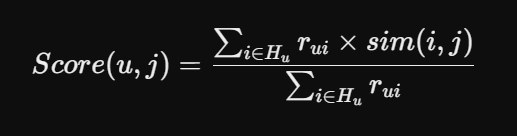

# where Hu represents the books highly rated by the user

In [51]:
def recommend(user_id, n=10):

  if user_id not in user_map:
    return "User not found"

  user_index = user_map[user_id]

  user_ratings = rating_matrix.getrow(user_index)

  rated_books = set(user_ratings.indices)

  high_rated_books = [
      (idx, rating)
      for idx, rating in zip(user_ratings.indices, user_ratings.data)
      if rating >= 8
  ]

  if not high_rated_books:
    return pd.DataFrame(columns=["Title", "Author", "Score"])

  scores = {}

  total_weight = sum(rating for idx, rating in high_rated_books)

  for book_idx, rating in high_rated_books:
    distances, indices = model.kneighbors(
        book_matrix[book_idx], n_neighbors=min(51, book_matrix.shape[0])
    )
    for distance, idx in zip(distances[0], indices[0]):
      candidate_isbn = book_info.loc[idx, "ISBN"]

      if idx in rated_books or candidate_isbn in previously_seen:
        continue

      similarity = 1 - distance

      if similarity <= 0:
        continue

      scores[idx] = scores.get(idx, 0) + (similarity * rating)

  ranked_books = sorted(scores.items(), key=lambda x: x[1], reverse=True)

  results = []

  for idx, score in ranked_books[:n]:
    results.append({
        "Title": book_info.loc[idx, "Book-Title"],
        "Author": book_info.loc[idx, "Book-Author"],
        "Score": round(score / total_weight, 4)
    })

  return pd.DataFrame(results)

In [52]:
# sanity check
def show_high_rated_books(user_id):
  if user_id not in user_map:
    return "User not found"

  user_index = user_map[user_id]

  user_ratings = rating_matrix.getrow(user_index)

  results = []

  for idx, rating in zip(user_ratings.indices, user_ratings.data):
    if rating >= 8:
      results.append({
          "Title": book_info.loc[idx, "Book-Title"], "Rating": rating
      })

  return pd.DataFrame(results, columns=['Title', 'Rating']).sort_values("Rating", ascending=False)

In [53]:
# choose three users with sufficient highly rated books
demo_users = (
    ratings[ratings["Book-Rating"]>=8].groupby("User-ID").size().sort_values(ascending=False).head(3).index.tolist()
)
print("selected users:", demo_users)

selected users: [11676, 104636, 153662]


In [54]:
# to display recommendations

for user_id in demo_users:

    print("=" * 70)
    print("USER ID:", user_id)

    print("\nHighly Rated Books:")
    display(show_high_rated_books(user_id))

    print("\nTop 10 Recommendations:")
    display(recommend(user_id, n=10))

USER ID: 11676

Highly Rated Books:


,Title,Rating
606,The Time Traveler'S Wife (Today Show Book Club...,10.0
605,The Time Traveler'S Wife,10.0
603,Tipping The Velvet,10.0
2,The Poisonwood Bible,10.0
3,Daughter Of Fortune : A Novel (Oprah'S Book Cl...,10.0
...,...,...
306,Island Of The Blue Dolphins (Laurel Leaf Books),8.0
311,Living Dead In Dallas (Southern Vampire Myster...,8.0
313,Neuromancer (Remembering Tomorrow),8.0
314,Stranger In A Strange Land (Remembering Tomorrow),8.0



Top 10 Recommendations:


,Title,Author,Score
0,"Night Shield (Intimate Moments, 1027)",Nora Roberts,0.0123
1,Public Secrets,Nora Roberts,0.0118
2,Palomino,Danielle Steel,0.0106
3,Birthright,Nora Roberts,0.0102
4,Night Tales,Nora Roberts,0.0097
5,Tears Of The Moon (Irish Trilogy),Nora Roberts,0.0092
6,Stanislaski Brothers (Silhouette Promo),Nora Roberts,0.0090
7,Perfect,Judith Mcnaught,0.0087
8,Conspiracy In Death,J. D. Robb,0.0085
9,A Perfect Stranger,Danielle Steel,0.0083


USER ID: 104636

Highly Rated Books:


,Title,Rating
0,Where The Sidewalk Ends : Poems And Drawings,10.0
4,Little House On The Prairie,10.0
9,Charlotte'S Web (Trophy Newbery),10.0
11,"The Lion, The Witch, And The Wardrobe (The Chr...",10.0
10,Bridge To Terabithia,10.0
...,...,...
160,Tarnished Gold (Landry),8.0
164,Every Breath You Take : A True Story Of Obsess...,8.0
158,All That Glitters (Landry),8.0
159,Hidden Jewel (Landry),8.0


... (2 outputs left out)

USER ID: 153662

Highly Rated Books:


,Title,Rating
0,The Divine Secrets Of The Ya-Ya Sisterhood: A ...,10.0
5,The Secret Garden,10.0
3,The Perfect Storm : A True Story Of Men Agains...,10.0
15,Pope Joan (Ballantine Reader'S Circle),10.0
16,Killjoy,10.0
...,...,...
80,Sea Swept (Quinn Brothers (Paperback)),8.0
129,Dead By Sunset : Dead By Sunset,8.0
119,Private Eyes (Alex Delaware Novels (Paperback)),8.0
105,Anne Of Ingleside (Anne Of Green Gables Novels...,8.0



Top 10 Recommendations:


,Title,Author,Score
0,Born In Shame,Nora Roberts,0.0490
1,Night Tales,Nora Roberts,0.0463
2,The Macgregors: Serena - Caine (The Macgregors),Nora Roberts,0.0403
3,Loyalty In Death,J. D. Robb,0.0380
4,Considering Kate (The Stanislaskis) (Silhouett...,Nora Roberts,0.0353
5,The Villa,Nora Roberts,0.0349
6,Paradise,Judith Mcnaught,0.0331
7,Ceremony In Death (Eve Dallas Mysteries (Paper...,J. D. Robb,0.0318
8,The Macgregors: Alan - Grant (The Macgregors),Nora Roberts,0.0310
9,When The Storm Breaks,Heather Lowell,0.0306


In [67]:
# to select three users for the recommendation demonstration

demo_users = [11676, 104636, 153662]

print("Selected users:", demo_users)

Selected users: [11676, 104636, 153662]


In [68]:
# to display highly rated books alongside personalized recommendations

for user_id in demo_users:

    print("=" * 100)
    print("USER ID:", user_id)

    # Retrieve highly rated books
    liked = show_high_rated_books(user_id).head(10)
    liked = liked[["Title", "Rating"]].reset_index(drop=True)

    # Retrieve recommended books
    recommended = recommend(user_id, n=10)
    recommended = recommended[
        ["Title", "Score"]
    ].reset_index(drop=True)

    # Rename columns for clarity
    liked.columns = ["Highly Rated Books", "Rating"]
    recommended.columns = ["Recommended Books", "Similarity Score"]

    # Combine both tables side by side
    result = pd.concat([liked, recommended], axis=1)

    result.index = result.index + 1

    display(result)

USER ID: 11676


,Highly Rated Books,Rating,Recommended Books,Similarity Score
1,The Time Traveler'S Wife (Today Show Book Club...,10.0,"Night Shield (Intimate Moments, 1027)",0.0123
2,The Time Traveler'S Wife,10.0,Public Secrets,0.0118
3,Tipping The Velvet,10.0,Palomino,0.0106
4,The Poisonwood Bible,10.0,Birthright,0.0102
5,Daughter Of Fortune : A Novel (Oprah'S Book Cl...,10.0,Night Tales,0.0097
6,Prodigal Summer,10.0,Tears Of The Moon (Irish Trilogy),0.0092
7,The Color Of Water: A Black Man'S Tribute To H...,10.0,Stanislaski Brothers (Silhouette Promo),0.0090
8,I Know This Much Is True (Oprah'S Book Club),10.0,Perfect,0.0087
9,Soul Harvest: The World Takes Sides (Left Behi...,10.0,Conspiracy In Death,0.0085
10,Tribulation Force: The Continuing Drama Of Tho...,10.0,A Perfect Stranger,0.0083


USER ID: 104636


,Highly Rated Books,Rating,Recommended Books,Similarity Score
1,Where The Sidewalk Ends : Poems And Drawings,10.0,The Gift,0.0392
2,Little House On The Prairie,10.0,The Face Of Fear,0.0321
3,Charlotte'S Web (Trophy Newbery),10.0,If There Be Thorns (Dollanganger),0.0310
4,"The Lion, The Witch, And The Wardrobe (The Chr...",10.0,Garden Of Shadows (Dollanger Saga (Paperback)),0.0293
5,Bridge To Terabithia,10.0,Five Days In Paris,0.0284
6,Secrets,10.0,The Anastasia Syndrome,0.0269
7,Harry Potter And The Prisoner Of Azkaban (Book 3),10.0,Midnight Bayou,0.0258
8,Talk Before Sleep,10.0,Seeds Of Yesterday (Dollanganger),0.0237
9,Harry Potter And The Goblet Of Fire (Book 4),10.0,Fallen Hearts,0.0231
10,Harry Potter And The Chamber Of Secrets (Book 2),10.0,The Endearment,0.0219


USER ID: 153662


,Highly Rated Books,Rating,Recommended Books,Similarity Score
1,The Divine Secrets Of The Ya-Ya Sisterhood: A ...,10.0,Born In Shame,0.0490
2,The Secret Garden,10.0,Night Tales,0.0463
3,The Perfect Storm : A True Story Of Men Agains...,10.0,The Macgregors: Serena - Caine (The Macgregors),0.0403
4,Pope Joan (Ballantine Reader'S Circle),10.0,Loyalty In Death,0.0380
5,Killjoy,10.0,Considering Kate (The Stanislaskis) (Silhouett...,0.0353
6,I Capture The Castle,10.0,The Villa,0.0349
7,Slammerkin,10.0,Paradise,0.0331
8,The Killer Angels,10.0,Ceremony In Death (Eve Dallas Mysteries (Paper...,0.0318
9,Fahrenheit 451,10.0,The Macgregors: Alan - Grant (The Macgregors),0.0310
10,The Fellowship Of The Ring (The Lord Of The Ri...,10.0,When The Storm Breaks,0.0306


In [58]:
# sanity checks
assert ratings["Book-Rating"].between(1, 10).all()

assert users["Age"].between(5, 100).all()

assert ratings["User-ID"].isin(users["User-ID"]).all()

assert ratings["ISBN"].isin(books["ISBN"]).all()

assert ratings.groupby("User-ID").size().min() >= MIN_RATINGS
assert ratings.groupby("ISBN").size().min() >= MIN_RATINGS

assert rating_matrix.nnz == len(ratings)

print("All data validation checks passed")

All data validation checks passed


In [62]:
# download generated data lake files
import shutil
from google.colab import files

os.makedirs("submission", exist_ok=True)

for folder in ["bronze", "silver", "gold"]:
    shutil.copytree(
        folder,
        f"submission/{folder}",
        dirs_exist_ok=True
    )

shutil.make_archive(
    "data_lake_submission",
    "zip",
    "submission"
)

files.download("data_lake_submission.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>